# Start here: how to run and read Model 2

**Run the notebook from top to bottom once.** The setup and race-data cache check are first. When the saved `lap_data_raw.csv` is found, the old race-download and single-race exploration cells are deliberately skipped. Those skipped cells have no output by design; the cache-check cell prints the reason.

| Notebook area | What it does | What you should see |
|---|---|---|
| Setup cells | Install/import libraries, enable FastF1 cache, and define the example race list. | Package/import messages and the race-list count. |
| Cache-check cell | Looks for `lap_data_raw.csv`, loads it once, and sets `DATA_CACHE_HIT`. | File path, saved lap count, event count, and whether downloads are skipped. |
| Legacy exploration block | Old schedule/API and one-race EDA steps. It runs only when the shared CSV is missing. | With the cache present, no output is expected from this block. |
| Section 10 | Records the gaps and what remains to be done. | Markdown explanation only. |
| Section 11A | Cleans the loaded data and summarizes laps/stints by compound. | Row counts and compound coverage. |
| Section 11B | Holds out complete stints and compares no-tire, linear/quadratic, and quantile models. | MAE/RMSE, interval coverage, and per-compound results. |
| Section 11C | Fits the final starter model, exports artifacts, plots tire-age curves, and shows one supported query. | Curve table, cliff summary, plot, and example prediction. |

If you open this notebook before running it, some code cells may have blank outputs. Outputs appear after those cells execute. The saved outputs in Section 11 are from the last run and can be refreshed by rerunning Sections 11A–11C.


In [1]:
%pip install fastf1 pandas numpy matplotlib seaborn scikit-learn xgboost scipy joblib


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 7.8 MB/s  0:00:01m 7.9 MB/s eta 0:00:01
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn]0m 4/5 [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import fastf1
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost
import scipy

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)


All libraries imported successfully!
Pandas: 2.3.3
NumPy: 2.2.6
Scikit-learn: 1.9.1
XGBoost: 3.4.1


In [3]:

import os
import fastf1

# Create cache directory
cache_dir = "fastf1_cache"

os.makedirs(cache_dir, exist_ok=True)

# Enable caching
fastf1.Cache.enable_cache(cache_dir)

print("FastF1 cache enabled successfully!")

FastF1 cache enabled successfully!


In [4]:
TARGET_YEAR = 2026

TARGET_RACES = [
    "Australia",
    "China",
    "Japan",
    "Miami",
    "Canada",
    "Monaco",
    "Barcelona-Catalunya",
    "Austria",
    "Great Britain",
    "Belgium",
    "Hungary",
    "Netherlands",
    "Italy",
    "Spain",
    "Azerbaijan",
    "Singapore"
]

print("Target Year:", TARGET_YEAR)
print("Total Target Races:", len(TARGET_RACES))

for race in TARGET_RACES:
    print(race)

Target Year: 2026
Total Target Races: 16
Australia
China
Japan
Miami
Canada
Monaco
Barcelona-Catalunya
Austria
Great Britain
Belgium
Hungary
Netherlands
Italy
Spain
Azerbaijan
Singapore


In [5]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lap_data_raw.csv").exists()),
    Path.cwd(),
)
MODEL2_DATA_PATH = PROJECT_ROOT / "lap_data_raw.csv"
DATA_CACHE_HIT = MODEL2_DATA_PATH.exists()

if DATA_CACHE_HIT:
    # Read the saved multi-event data once; Section 11 reuses this dataframe.
    raw_df = pd.read_csv(MODEL2_DATA_PATH, low_memory=False)
    print(f"Found saved race data: {MODEL2_DATA_PATH}")
    print(f"Loaded {len(raw_df):,} laps across {raw_df['EventName'].nunique()} events.")
    print("Skipping schedule/session downloads and the older single-race API cells.")
else:
    raw_df = None
    print(f"No saved race dataset found at {MODEL2_DATA_PATH}.")
    print("The legacy exploration cells will run; Model 2 training needs the shared multi-event lap_data_raw.csv.")


Found saved race data: /Users/hemant/Work/StintIQ/lap_data_raw.csv
Loaded 19,644 laps across 17 events.
Skipping schedule/session downloads and the older single-race API cells.


### Optional legacy race download and single-race exploration

The cells below are retained from the initial notebook. They cover schedule lookup, FastF1/OpenF1 requests, lap/stint merging, weather matching, and exploratory plots. Each is guarded by `if not DATA_CACHE_HIT:`. Since this project already has `lap_data_raw.csv`, the condition is false and these cells intentionally do nothing. Continue to Section 11 for the active Model 2 pipeline.

In [6]:
if not DATA_CACHE_HIT:
    schedule_2026 = fastf1.get_event_schedule(
        TARGET_YEAR,
        include_testing=False
    )

    display(
        schedule_2026[
            schedule_2026["EventName"].str.contains(
                "|".join(TARGET_RACES),
                case=False,
                na=False,
                regex=True
            )
        ][["RoundNumber", "EventName", "EventDate"]]
    )

In [7]:
if not DATA_CACHE_HIT:
    # Display complete 2026 F1 race schedule

    display(
        schedule_2026.reset_index(drop=True)[
            ["RoundNumber", "EventName", "EventDate"]
        ]
    )

In [8]:
if not DATA_CACHE_HIT:
    # Display complete 2026 F1 race schedule

    display(
        schedule_2026.reset_index(drop=True)[
            ["RoundNumber", "EventName", "EventDate"]
        ]
    )

In [9]:
if not DATA_CACHE_HIT:
    # Map Model 1 race list to FastF1 event names

    race_mapping = {
        "Australia": "Australian Grand Prix",
        "China": "Chinese Grand Prix",
        "Japan": "Japanese Grand Prix",
        "Miami": "Miami Grand Prix",
        "Canada": "Canadian Grand Prix",
        "Monaco": "Monaco Grand Prix",
        "Barcelona-Catalunya": "Barcelona Grand Prix",
        "Austria": "Austrian Grand Prix",
        "Great Britain": "British Grand Prix",
        "Belgium": "Belgian Grand Prix",
        "Hungary": "Hungarian Grand Prix",
        "Netherlands": "Dutch Grand Prix",
        "Italy": "Italian Grand Prix",
        "Spain": "Spanish Grand Prix",
        "Azerbaijan": "Azerbaijan Grand Prix",
        "Singapore": "Singapore Grand Prix"
    }

    selected_events = schedule_2026[
        schedule_2026["EventName"].isin(race_mapping.values())
    ].copy()

    display(
        selected_events[
            ["RoundNumber", "EventName", "EventDate"]
        ].reset_index(drop=True)
    )

    print("Selected races:", len(selected_events))

In [10]:
if not DATA_CACHE_HIT:
    # Load first selected race as a test

    test_event = selected_events.iloc[0]["EventName"]

    test_session = fastf1.get_session(
        TARGET_YEAR,
        test_event,
        "R"
    )

    test_session.load(
        laps=True,
        telemetry=False,
        weather=True,
        messages=False
    )

    print("Race:", test_event)
    print("Session loaded successfully!")
    print("Total laps:", len(test_session.laps))

In [11]:
if not DATA_CACHE_HIT:
    import requests
    import pandas as pd

    # OpenF1 session key for 2026 Australian Grand Prix
    session_key = 11234

    url = "https://api.openf1.org/v1/laps"

    response = requests.get(
        url,
        params={"session_key": session_key},
        timeout=30
    )

    print("HTTP Status:", response.status_code)

    if response.status_code == 200:
        openf1_test = pd.DataFrame(response.json())

        print("Total lap records:", len(openf1_test))
        display(openf1_test.head())

    else:
        print("API request failed.")
        print(response.text[:500])

In [12]:
if not DATA_CACHE_HIT:
    # Fetch tire stint information from OpenF1

    stints_url = "https://api.openf1.org/v1/stints"

    stints_response = requests.get(
        stints_url,
        params={"session_key": session_key},
        timeout=30
    )

    print("HTTP Status:", stints_response.status_code)

    if stints_response.status_code == 200:

        stints_data = pd.DataFrame(stints_response.json())

        print("Total stint records:", len(stints_data))
        print("\nAvailable columns:")
        print(stints_data.columns.tolist())

        display(stints_data.head(10))

    else:
        print("Stint data request failed.")
        print(stints_response.text[:500])

In [13]:
if not DATA_CACHE_HIT:
    # Merge lap data with tire stint information

    merged_data = openf1_test.merge(
        stints_data,
        on=["meeting_key", "session_key", "driver_number"],
        how="inner"
    )

    # Keep only laps that fall within the corresponding stint
    merged_data = merged_data[
        (merged_data["lap_number"] >= merged_data["lap_start"]) &
        (merged_data["lap_number"] <= merged_data["lap_end"])
    ].copy()

    # Calculate tire age for each lap
    merged_data["tire_age"] = (
        merged_data["tyre_age_at_start"] +
        merged_data["lap_number"] -
        merged_data["lap_start"]
    )

    print("Total merged lap records:", len(merged_data))

    print("\nAvailable columns:")
    print(merged_data.columns.tolist())

    display(
        merged_data[
            ["driver_number", "lap_number", "compound",
             "stint_number", "tire_age", "lap_duration"]
        ].head(15)
    )

In [14]:
if not DATA_CACHE_HIT:
    # Check missing values
    print("Missing values:")
    print(merged_data[
        ["lap_duration", "compound", "tire_age", "lap_number"]
    ].isnull().sum())

    # Check tire compounds
    print("\nTire compounds:")
    print(merged_data["compound"].value_counts())

    # Check tire age range
    print("\nTire age statistics:")
    print(merged_data["tire_age"].describe())

    # Check pit-out laps
    print("\nPit-out laps:")
    print(merged_data["is_pit_out_lap"].value_counts(dropna=False))

    # Check duplicate lap records
    print("\nDuplicate lap records:")
    print(
        merged_data.duplicated(
            subset=["driver_number", "lap_number", "stint_number"]
        ).sum()
    )

In [15]:
if not DATA_CACHE_HIT:
    # Remove missing lap times and pit-out laps

    clean_data = merged_data.dropna(
        subset=["lap_duration"]
    ).copy()

    clean_data = clean_data[
        clean_data["is_pit_out_lap"] == False
    ].copy()

    # Keep only realistic positive lap durations
    clean_data = clean_data[
        clean_data["lap_duration"] > 0
    ].copy()

    clean_data.reset_index(drop=True, inplace=True)

    print("Original records:", len(merged_data))
    print("Clean records:", len(clean_data))
    print("Removed records:", len(merged_data) - len(clean_data))

    print("\nRemaining missing values:")
    print(clean_data[
        ["lap_duration", "compound", "tire_age"]
    ].isnull().sum())

    display(clean_data.head())

In [16]:
if not DATA_CACHE_HIT:
    # Fetch weather data from OpenF1

    weather_url = "https://api.openf1.org/v1/weather"

    weather_response = requests.get(
        weather_url,
        params={"session_key": session_key},
        timeout=30
    )

    print("HTTP Status:", weather_response.status_code)

    if weather_response.status_code == 200:

        weather_data = pd.DataFrame(weather_response.json())

        print("Total weather records:", len(weather_data))
        print("\nAvailable columns:")
        print(weather_data.columns.tolist())

        display(weather_data.head(10))

    else:
        print("Weather data request failed.")
        print(weather_response.text[:500])

In [17]:
if not DATA_CACHE_HIT:
    # Convert timestamps (supports mixed ISO formats)

    clean_data["date_start"] = pd.to_datetime(
        clean_data["date_start"],
        format="mixed",
        utc=True
    )

    weather_data["date"] = pd.to_datetime(
        weather_data["date"],
        format="mixed",
        utc=True
    )


    clean_data = clean_data.sort_values("date_start")
    weather_data = weather_data.sort_values("date")


    clean_data = pd.merge_asof(
        clean_data,
        weather_data.drop(columns=["session_key", "meeting_key"]),
        left_on="date_start",
        right_on="date",
        direction="nearest",
        tolerance=pd.Timedelta("2min")
    )

    print("Weather data merged successfully!")

    print("\nMissing weather values:")
    print(
        clean_data[
            ["air_temperature", "track_temperature",
             "humidity", "rainfall", "wind_speed"]
        ].isnull().sum()
    )

    display(
        clean_data[
            ["driver_number", "lap_number", "tire_age",
             "compound", "lap_duration",
             "air_temperature", "track_temperature", "rainfall"]
        ].head(10)
    )

In [18]:
if not DATA_CACHE_HIT:
    # Check all available columns

    print("Total columns:", len(clean_data.columns))

    print("\nAvailable columns:")
    for col in clean_data.columns:
        print(col)

    fuel_columns = [
        col for col in clean_data.columns
        if "fuel" in col.lower()
    ]

    print("\nFuel-related columns:", fuel_columns)

    track_columns = [
        col for col in clean_data.columns
        if any(word in col.lower() for word in ["track", "circuit"])
    ]

    print("\nTrack-related columns:", track_columns)

In [19]:
if not DATA_CACHE_HIT:
    # Analyze lap times for each tire compound

    compound_summary = clean_data.groupby("compound")["lap_duration"].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).round(3)

    print("Lap Time Summary by Tire Compound:")
    display(compound_summary)

    print("\nAverage tire age by compound:")
    display(
        clean_data.groupby("compound")["tire_age"]
        .mean()
        .round(2)
    )

In [20]:
if not DATA_CACHE_HIT:
    # Identify unusually slow lap records

    print("Overall Lap Time Statistics:")
    display(clean_data["lap_duration"].describe())

    # Find laps taking more than 110 seconds
    abnormal_laps = clean_data[
        clean_data["lap_duration"] > 110
    ]

    print("\nAbnormal lap records:", len(abnormal_laps))

    display(
        abnormal_laps[
            ["driver_number", "lap_number", "stint_number",
             "compound", "tire_age", "lap_duration",
             "is_pit_out_lap"]
        ].sort_values("lap_duration", ascending=False).head(15)
    )

In [21]:
if not DATA_CACHE_HIT:
    # Inspect abnormal laps with sector timings

    abnormal_details = abnormal_laps[
        [
            "driver_number",
            "lap_number",
            "stint_number",
            "compound",
            "tire_age",
            "duration_sector_1",
            "duration_sector_2",
            "duration_sector_3",
            "lap_duration"
        ]
    ].sort_values("lap_duration", ascending=False)

    display(abnormal_details.head(20))

In [22]:
if not DATA_CACHE_HIT:
    # Remove incomplete and extreme lap records

    before_cleaning = len(clean_data)

    model_data = clean_data.dropna(
        subset=[
            "duration_sector_1",
            "duration_sector_2",
            "duration_sector_3",
            "lap_duration"
        ]
    ).copy()

    model_data = model_data[
        model_data["lap_duration"] < 110
    ].copy()

    model_data.reset_index(drop=True, inplace=True)

    print("Records before cleaning:", before_cleaning)
    print("Records after cleaning:", len(model_data))
    print("Records removed:", before_cleaning - len(model_data))

    display(
        model_data["lap_duration"].describe().round(3)
    )

In [23]:
if not DATA_CACHE_HIT:
    # Analyze tire degradation trend

    degradation_summary = model_data.groupby(
        ["compound", "tire_age"]
    )["lap_duration"].agg(
        ["count", "mean", "median"]
    ).reset_index()

    degradation_summary = degradation_summary.round(3)

    print("Tire Age vs Lap Time Summary:")
    display(degradation_summary.head(20))

In [31]:
if not DATA_CACHE_HIT:
    # Plot tire age vs average lap time for each compound

    plt.figure(figsize=(12, 6))

    for compound in degradation_summary["compound"].unique():

        compound_data = degradation_summary[
            (degradation_summary["compound"] == compound) &
            (degradation_summary["count"] >= 5)
        ]

        plt.plot(
            compound_data["tire_age"],
            compound_data["mean"],
            marker="o",
            label=compound
        )

    plt.title("Tire Age vs Average Lap Time")
    plt.xlabel("Tire Age (Laps)")
    plt.ylabel("Average Lap Time (Seconds)")
    plt.legend(title="Tire Compound")
    plt.grid(True)
    plt.show()

In [25]:
if not DATA_CACHE_HIT:
    # Investigate unusually slow age-0 laps

    age_zero_data = model_data[
        model_data["tire_age"] == 0
    ][
        [
            "driver_number",
            "lap_number",
            "stint_number",
            "compound",
            "lap_start",
            "lap_end",
            "duration_sector_1",
            "duration_sector_2",
            "duration_sector_3",
            "lap_duration",
            "is_pit_out_lap"
        ]
    ].sort_values("lap_duration", ascending=False)

    print("Total age-0 records:", len(age_zero_data))

    display(age_zero_data)

In [26]:
if not DATA_CACHE_HIT:
    # Exclude age-0 laps from degradation analysis

    analysis_data = model_data[
        model_data["tire_age"] > 0
    ].copy()

    analysis_data.reset_index(drop=True, inplace=True)

    print("Records before age-0 exclusion:", len(model_data))
    print("Age-0 records excluded:", len(model_data[model_data["tire_age"] == 0]))
    print("Records for degradation analysis:", len(analysis_data))

    print("\nTire age distribution:")
    display(
        analysis_data.groupby("compound")["tire_age"].agg(
            ["count", "min", "max", "mean"]
        ).round(2)
    )

In [32]:
if not DATA_CACHE_HIT:
    # Calculate median lap time by tire age and compound

    final_degradation_summary = analysis_data.groupby(
        ["compound", "tire_age"]
    ).agg(
        count=("lap_duration", "count"),
        median_lap_time=("lap_duration", "median")
    ).reset_index()

    # Plot updated degradation curves

    plt.figure(figsize=(12, 6))

    for compound in final_degradation_summary["compound"].unique():

        compound_data = final_degradation_summary[
            (final_degradation_summary["compound"] == compound) &
            (final_degradation_summary["count"] >= 5)
        ]

        plt.plot(
            compound_data["tire_age"],
            compound_data["median_lap_time"],
            marker="o",
            label=compound
        )

    plt.title("Updated Tire Degradation Curve")
    plt.xlabel("Tire Age (Laps)")
    plt.ylabel("Median Lap Time (Seconds)")
    plt.legend(title="Tire Compound")
    plt.grid(True)
    plt.show()

## 10. Model 2 Gap Analysis and Completion Plan

> **Review status:** This section records the pre-build gap review. Section 11 now adds the first working non-tire-baseline and tire-residual model, held-out-stint evaluation, and saved curve artifacts. The remaining limitations are called out below.

### What is already present

- A first-session data pull, lap/stint join, tire-age calculation, weather join, basic data checks, and plots of lap time against tire age and compound.
- A draft race list, although the processing cells currently load and analyze only the Australian race.

### Gaps and status after the first implementation

1. **Target confounding is reduced, not eliminated.** The original plots use raw lap seconds. Section 11 adds a cross-fitted baseline that excludes tire age, compound, stint, and lag features, then models its residuals. Fuel is still an estimated proxy and the baseline includes race progress as a track-evolution control, so sensitivity checks are required.
2. **The main model now uses the shared source and core cleaning rules.** Section 11 reads `lap_data_raw.csv`, keeps accurate dry green-flag laps, removes pit-in/out laps, and applies the project’s event-best +8% extreme-lap guardrail. That guardrail is an initial retrospective cleaning choice, not a live rule. The older single-Australia OpenF1 cells remain exploratory.
3. **The trained pipeline inherits Model 1's raw `TyreLife` field.** It does not recalculate tire age, avoiding the one-lap mismatch in the older OpenF1 exploration cells. Keep the raw/API formula aligned if that path is reused.
4. **A first fitted curve, quantile interval, and pooled change-point estimate now exist.** The curve is relative to tire age 5; the cliff estimate is pooled by compound across circuits and has no independent ground-truth validation. Intervals and cliff stability need further calibration.
5. **A held-out-stint evaluation and saved artifacts now exist.** The split still contains other stints from the same events, so it is not a leave-one-event-out or live rolling-origin backtest. Model 3 integration and extrapolation-safe serving are not complete.

### Resolve the Model 1 handoff before fitting

Model 1 predicts `lap_time_delta` using both `TyreLife` and `Compound`. Its residuals therefore may already have had some tire-age and compound effect explained away. Feeding those residuals directly into Model 2 can understate degradation; adding a full degradation curve to Model 1 predictions could also count tire effects twice. Define the decomposition first: train or generate a **non-tire baseline** that excludes tire age and compound, then let Model 2 estimate the tire contribution, or define another explicit target that removes fuel and other nuisance effects while preserving the tire signal. Use out-of-fold or strictly past-only baseline predictions. For live backtests, also fix two current Model 1 information-boundary issues: its event reference is the minimum clean lap over the full event, and missing first-lap lag values are filled from that lap's own target. Neither should expose future target information.

### Remaining work to complete, in order

| Step | Work | Deliverable / check |
|---|---|---|
| 1. Standardize the input | Reuse `lap_data_raw.csv` (or extend the shared data pipeline) so each row has event/circuit, driver/team, stint, compound, tire age, lap time, fuel proxy, track/air temperature, weather regime, track status, and pit-in/out flags. Normalize names and types; reconcile the tire-age convention. Start with dry slick stints and keep wet/transition regimes separate. | One documented lap-level schema with duplicate, missingness, stint-boundary, and age checks. |
| 2. Clean and define the target | Remove invalid, pit-in/out, and non-green laps using available session flags; replace the global 110-second cutoff with event-aware, reference-relative outlier checks. Build fuel-corrected pace delta and document the fuel correction and its sensitivity. Control for driver/car baseline, traffic, weather, and track evolution without removing the tire-age/compound signal. | A reproducible modeling table and written target equation. |
| 3. Fit interpretable baselines | Estimate per-stint linear/quadratic degradation curves by compound first. Then compare a nonlinear GBT model with compound, tire age, circuit/abrasiveness, temperature, and relevant controls. Pool sparse circuits carefully rather than fitting unsupported circuit-specific curves. | Baseline and nonlinear predictions with pace loss per tire lap. |
| 4. Improve cliff behavior | The first version estimates a pooled compound change point with a stint bootstrap. Next, check stability, compare age grids, and add circuit-level estimates only where there is enough support. Do not report one exact cliff lap when evidence is weak. | Cliff candidate/interval with support status; explicit no-cliff outcome when unsupported. |
| 5. Validate without leakage | Keep every stint wholly in one fold; report held-out-stint MAE against the simple baselines, stratified by compound/circuit/tire-age range. Add an event/time holdout for transfer, cliff detection within ±2 laps where a reference label is defensible, extrapolation stress tests, and ablations for fuel, traffic, weather, and track evolution. Use only information available by the prediction lap in backtests. | A results table, residual checks, coverage/calibration for uncertainty, and documented limitations. |
| 6. Export and connect | The first version saves a fitted bundle, curve table, evaluation summary, and a support-checked `predict_tire_pace_loss` query. Next, connect that query to Model 3 and ensure the non-tire baseline plus tire curve replace (rather than stack on) the tire-aware Model 1 output. | Reproducible artifact and an integrated Model 3 prediction path. |

### Definition of done

Model 2 is ready for downstream use when the full multi-event pipeline runs from the shared source data; the target and Model 1 decomposition are documented; held-out-stint performance is compared with interpretable baselines; errors and cliff behavior are reported by compound/circuit with uncertainty and extrapolation limits; and a versioned output can supply Model 3 with tire-age pace loss and uncertainty. Do not treat the current raw-time median plots as evidence that the model is validated.

## 11. First Model 2 Implementation: Non-Tire Baseline + Tire Residuals

This section is the first runnable end-to-end Model 2 pipeline. It uses the shared `lap_data_raw.csv`, creates a separate non-tire pace baseline with cross-fitted predictions, fits tire-age/compound quantile curves on the remaining pace residual, and estimates a pooled compound change point with a stint bootstrap. It does **not** modify the existing Model 1 notebook.

The initial validation holds out complete stints, but other stints from the same events can remain in training. Treat the metrics as a first research check, not a live or unseen-circuit result. The cliff estimate is pooled across circuits and must not be read as a circuit-specific physical limit.

### Section 11A — Prepare the modeling table

Reuses the dataframe loaded by the cache-check cell (no second CSV read). It keeps accurate, dry, green-flag laps, removes pit-in/out laps, applies the current event-level outlier guardrail, and displays how much data remains by compound. Run this before 11B or 11C.

In [28]:
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lap_data_raw.csv').exists()),
    Path.cwd(),
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from model2_tire_degradation import prepare_model2_data, evaluate_model2, train_final_model2, predict_tire_pace_loss

if not DATA_CACHE_HIT:
    raise FileNotFoundError('Model 2 needs the shared multi-event lap_data_raw.csv. Save or select it before training.')
model2_frame, model2_data_summary = prepare_model2_data(raw_df)
display(pd.Series(model2_data_summary, name='Value').to_frame())
display(model2_frame.groupby('Compound').agg(
    Laps=('TyreLife', 'size'),
    Stints=('StintKey', 'nunique'),
    MaxAge=('TyreLife', 'max'),
).reset_index())

,Value
raw_rows,19644
after_quality_filters,17871
after_event_outlier_guardrail,15193
removed_duplicate_keys,0
events,17
circuits,17
stints,843
compound_laps,"{'HARD': 6744, 'MEDIUM': 5368, 'SOFT': 3081}"
tire_age_range,"[1.0, 61.0]"


,Compound,Laps,Stints,MaxAge
0,HARD,6744,303,54.0
1,MEDIUM,5368,314,60.0
2,SOFT,3081,226,61.0


### Section 11B — Check performance on held-out stints

Splits by complete event-driver-stint groups so laps from the same stint do not land on both sides. It compares a zero tire-effect baseline, a simple linear/quadratic curve, and the quantile model. The results are preliminary: events can still appear in both train and test through different stints.

In [29]:
# Grouped split is by complete event-driver-stint, never by random lap row.
model2_metrics, model2_holdout = evaluate_model2(model2_frame)

display(pd.Series({k: v for k, v in model2_metrics.items() if k != 'per_compound'}, name='Value').to_frame())
display(pd.DataFrame.from_dict(model2_metrics['per_compound'], orient='index').rename_axis('Compound'))

model2_output_dir = PROJECT_ROOT / 'models'
model2_output_dir.mkdir(exist_ok=True)
(model2_output_dir / 'model2_evaluation.json').write_text(
    __import__('json').dumps(model2_metrics, indent=2)
)
model2_holdout['predictions'].to_csv(model2_output_dir / 'model2_holdout_predictions.csv', index=False)

,Value
train_laps,11514
test_laps,3679
train_stints,632
test_stints,211
train_events,17
test_events,17
zero_tire_effect_mae_sec,0.659213
linear_quadratic_tire_mae_sec,0.651585
model2_median_mae_sec,0.621176
model2_median_rmse_sec,0.843589


,test_laps,test_stints,zero_tire_effect_mae_sec,linear_quadratic_tire_mae_sec,model2_median_mae_sec,q10_q90_coverage_pct
Compound,,,,,,
HARD,1574,72,0.647029,0.642207,0.611497,81.067344
MEDIUM,1369,85,0.660880,0.633508,0.624777,79.327977
SOFT,736,54,0.682166,0.705267,0.635176,83.967391


### Section 11C — Fit and inspect the starter model

Refits using all available stints, saves the model and curve/evaluation files under `models/`, displays a supported circuit curve, and demonstrates the support-checked prediction function. The pooled cliff bootstrap takes longer than the other cells. It currently reports no reliable cliff; this is not a full strategy-ready model.

,CircuitName,Compound,TrackTempReferenceC,TyreLife,ReferenceTyreLife,PaceLossQ10Sec,PaceLossQ50Sec,PaceLossQ90Sec,NStints,NLaps,ObservedAgeMax,SupportFlag
0,Australia,HARD,36.2,1,5,-1.023185,1.862022,3.849772,21,485,46.0,supported_range
1,Australia,HARD,36.2,2,5,-1.023185,-0.121790,1.350368,21,485,46.0,supported_range
2,Australia,HARD,36.2,3,5,-1.023185,-0.121790,1.350368,21,485,46.0,supported_range
3,Australia,HARD,36.2,4,5,-0.937582,-0.014004,1.350368,21,485,46.0,supported_range
4,Australia,HARD,36.2,5,5,-0.781311,0.000000,1.350368,21,485,46.0,supported_range
5,Australia,HARD,36.2,6,5,-0.781311,-0.016065,1.350368,21,485,46.0,supported_range
6,Australia,HARD,36.2,7,5,-0.781311,-0.014418,1.350368,21,485,46.0,supported_range
7,Australia,HARD,36.2,8,5,-0.781311,-0.010808,1.350368,21,485,46.0,supported_range
8,Australia,HARD,36.2,9,5,-0.766198,-0.010808,1.350368,21,485,46.0,supported_range
9,Australia,HARD,36.2,10,5,-0.688198,-0.010808,1.350368,21,485,46.0,supported_range


,Compound,NStints,NLaps,CandidateCliffAge,CliffAgeQ10,CliffAgeQ90,BICImprovement,BootstrapSupportPct,CliffDetected,Status
0,SOFT,226,3081,14,NaN,NaN,-4.829621,0.0,False,no reliable cliff detected
1,MEDIUM,314,5368,12,NaN,NaN,-4.582295,0.0,False,no reliable cliff detected
2,HARD,303,6744,10,NaN,NaN,-0.611000,0.0,False,no reliable cliff detected


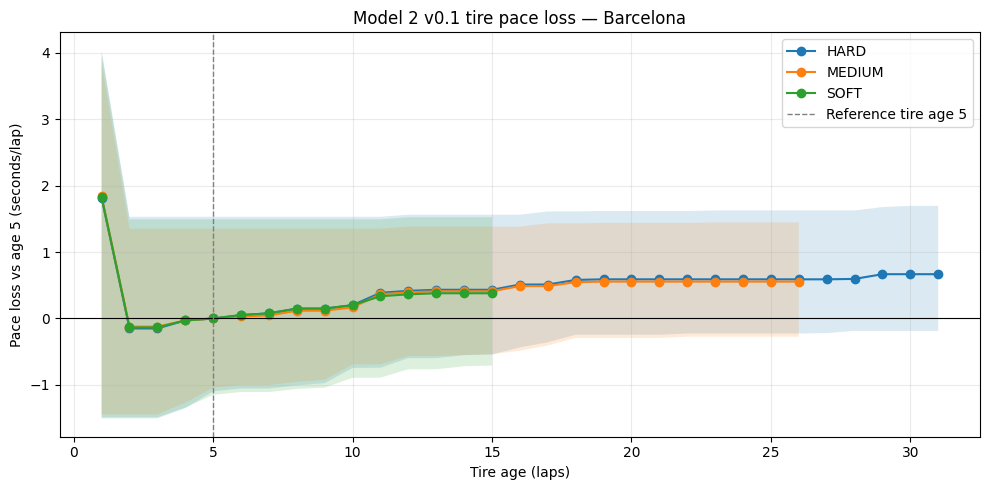

,Model 3 query example
supported,True
compound,HARD
circuit_name,Barcelona
tire_age,15.0
track_temp_c,49.8
reference_tire_age,5.0
pace_loss_q10_sec,-0.540277
pace_loss_q50_sec,0.432207
pace_loss_q90_sec,1.561582
n_stints,37


Saved: /Users/hemant/Work/StintIQ/models/model2_tire_pace_loss.joblib
Saved: /Users/hemant/Work/StintIQ/models/model2_degradation_curves.csv


In [30]:
# Refit cross-fitted residuals on all available stints and export the v0.1 artifact.
model2_bundle, model2_curve = train_final_model2(
    model2_frame, model2_output_dir, model2_data_summary
)
display(model2_curve.head(12))
display(pd.DataFrame(model2_bundle['pooled_compound_cliff_estimates']))

# Inspect a supported circuit's age curve; the pooled cliff summary is shown above.
import matplotlib.pyplot as plt
if not model2_curve.empty:
    circuit_support = model2_curve.groupby('CircuitName')['NStints'].max().sort_values(ascending=False)
    selected_circuit = circuit_support.index[0]
    plot_data = model2_curve[model2_curve['CircuitName'] == selected_circuit]
    fig, ax = plt.subplots(figsize=(10, 5))
    for compound, part in plot_data.groupby('Compound'):
        part = part.sort_values('TyreLife')
        ax.plot(part['TyreLife'], part['PaceLossQ50Sec'], marker='o', label=compound)
        ax.fill_between(part['TyreLife'], part['PaceLossQ10Sec'], part['PaceLossQ90Sec'], alpha=0.16)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(5, color='grey', linestyle='--', linewidth=1, label='Reference tire age 5')
    ax.set(title=f'Model 2 v0.1 tire pace loss — {selected_circuit}', xlabel='Tire age (laps)', ylabel='Pace loss vs age 5 (seconds/lap)')
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    example_curve = plot_data.sort_values('TyreLife')
    example = predict_tire_pace_loss(
        model2_bundle,
        compound=example_curve['Compound'].iloc[0],
        circuit_name=selected_circuit,
        tire_age=min(15.0, float(example_curve['ObservedAgeMax'].iloc[0])),
        track_temp_c=float(example_curve['TrackTempReferenceC'].iloc[0]),
    )
    display(pd.Series(example, name='Model 3 query example').to_frame())
else:
    print('No circuit-compound combination met the minimum support rules.')

print('Saved:', model2_output_dir / 'model2_tire_pace_loss.joblib')
print('Saved:', model2_output_dir / 'model2_degradation_curves.csv')